# LatAm FX volatility: cones, risk premium and relative value

A worked notebook that rebuilds the analysis step by step, so you can check every number and change any assumption.

**Contents**
1. Setup and loading the Bloomberg export
2. Data quality: holidays, big moves, stale prints
3. Realized volatility, done carefully
4. Option basics you need: vega, and why short vol P&L ≈ vega × (implied − realized)
5. The volatility cone
6. Skew snapshot: risk reversals and butterflies vs history
7. The volatility risk premium (VRP), measured properly
8. Across LatAm: comparing pairs, and the equal-vega basket
9. Relative value: a vega-neutral long/short backtest with daily marking and costs
10. How much marking with constant-maturity 3M vol matters
11. Diagnosing the result: where the P&L comes from
12. Checklist before you show this to a vol trader, and exercises

**How to use it.** Put `latam_fx_1.xlsx` in the same folder and run top to bottom (the backtest cells take a few minutes). Cells marked **Try it** are good places to change a parameter and see what moves.

## 1. Setup and loading the Bloomberg export

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from math import erf, sqrt, exp, pi

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.figsize": (11, 5), "axes.grid": True,
                     "grid.linestyle": "--", "grid.alpha": .5})

FILE   = "latam_fx_1.xlsx"
PAIRS  = ["COP", "MXN", "BRL", "CLP", "PEN"]
TENORS = {"3M": 3, "6M": 6, "9M": 9, "1Y": 12}     # tenor -> months
DAYS_PER_YEAR = 365                                # implied vols are quoted on calendar time (ACT/365)

Each pair's sheet is a raw Bloomberg BDH export: tickers sit in row 6, data starts in row 9, dates in column B. (The workbook's other sheets, credit/expectations and COP REER, aren't used in this notebook.) The helper below turns each sheet into a tidy frame with short column names:

| column | meaning | units |
|---|---|---|
| `spot` | USD/xxx spot | local currency per USD |
| `atm_3M` … `atm_1Y` | at-the-money implied vol | vol %, e.g. 14.5 |
| `rr_3M`, `rr_6M`, `rr_1Y` | 25-delta risk reversal: vol of 25d USD call − 25d USD put | vol points |
| `bf25_3M` … `bf25_1Y` | 25-delta butterfly: average 25d wing vol − ATM vol | vol points |
| `bf15_3M` … `bf15_1Y` | 15-delta butterfly: the same, further out in the wings | vol points |

A positive RR means USD calls (local-currency weakness) are priced above USD puts, which is normal for EM currencies. The BF measures how expensive both wings are relative to ATM, i.e. how fat-tailed the market thinks the distribution is.

In [2]:
def load_sheet(raw):
    ncol = raw.shape[1]
    tickers = [str(t).strip() for t in raw.iloc[5, 2:ncol]]
    df = raw.iloc[8:, 1:ncol].copy()
    df.columns = ["date"] + tickers
    df["date"] = pd.to_datetime(df["date"])
    return df.set_index("date").apply(pd.to_numeric, errors="coerce")

def tidy(df, pair):
    cols = {c.upper(): c for c in df.columns}          # tickers mix '1Y' and '1y'
    out = pd.DataFrame(index=df.index)
    out["spot"] = df[cols[f"USD{pair} CURNCY"]]
    for t in TENORS:
        out[f"atm_{t}"] = df[cols[f"USD{pair}V{t} BGN CURNCY"]]
    for t in ["3M", "6M", "1Y"]:
        out[f"rr_{t}"] = df[cols[f"USD{pair}25R{t} BGN CURNCY"]]
        out[f"bf15_{t}"] = df[cols[f"USD{pair}15B{t} BGN CURNCY"]]
        out[f"bf25_{t}"] = df[cols[f"USD{pair}25B{t} BGN CURNCY"]]
    return out

raw  = pd.read_excel(FILE, sheet_name=PAIRS, header=None)   # other sheets in the file are not used here
data = {p: tidy(load_sheet(raw[p]), p) for p in PAIRS}
print(data["COP"].tail(3).T)

date     2026-10-23  2026-10-26  2026-10-27
spot      3146.2300   3130.8000    3147.050
atm_3M      14.3450     14.5225      14.630
atm_6M      14.4400     14.4475      14.460
atm_9M      14.3900     14.3925      14.355
atm_1Y      14.4050     14.4025      14.405
rr_3M        2.6800      2.7075       2.605
bf15_3M      1.2425      1.2725       1.240
bf25_3M      0.6050      0.6225       0.570
rr_6M        2.6600      2.6550       2.585
bf15_6M      1.3175      1.3575       1.365
bf25_6M      0.6850      0.6950       0.705
rr_1Y        2.6900      2.6550       2.610
bf15_1Y      1.4550      1.4525       1.450
bf25_1Y      0.7575      0.7525       0.720


## 2. Data quality: always look before you compute

Three things to check in any Bloomberg FX history:

* **Holidays.** The export is on a weekday calendar. On a local holiday Bloomberg repeats the previous price, so the return is exactly zero. How you annualize decides whether those zeros bias realized vol (section 3).
* **Huge moves.** Real events (elections, devaluations) or bad ticks. You need to know which.
* **Snapshot timing.** The last row of an export can be an intraday snapshot that gets revised at the close. Re-pull before you trust the latest day.

In [3]:
rows = []
for p in PAIRS:
    s = data[p]["spot"]; r = np.log(s).diff()
    yrs = (s.index[-1] - s.index[0]).days / DAYS_PER_YEAR
    big = r.abs().idxmax()
    rows.append(dict(pair=p, obs=len(s), missing=int(data[p].isna().sum().sum()),
                     zero_change_days=int((s.diff() == 0).sum()),
                     true_trading_days_per_year=round(((s.diff() != 0).sum()) / yrs, 1),
                     biggest_move_date=big.date(), biggest_move_pct=round(r[big] * 100, 2)))
print(pd.DataFrame(rows).set_index("pair"))
print()
print(data["BRL"][["spot", "atm_3M", "atm_6M", "rr_3M"]].tail(5))

       obs  missing  zero_change_days  true_trading_days_per_year biggest_move_date  biggest_move_pct
pair                                                                                                 
COP   3345        0               223                       243.4        2014-12-02              6.02
MXN   3345        0                 3                       260.5        2016-11-09              7.98
BRL   3345        0               142                       249.7        2026-10-26              8.40
CLP   3345        0               130                       250.6        2022-07-15             -7.37
PEN   3345        0               200                       245.2        2021-07-30              3.55

              spot  atm_3M  atm_6M   rr_3M
date                                      
2026-10-21  5.0240  17.765  16.238  5.8450
2026-10-22  5.0451  18.170  16.493  6.1300
2026-10-23  4.9790  16.165  14.980  3.0725
2026-10-26  5.4153  15.823  15.298  2.7825
2026-10-27  5.3450  14.780 

**Reading this**

* COP, PEN, BRL and CLP have 130–220 zero-change days, roughly one per local holiday, so they really trade only about 243–251 days a year. MXN has almost none and trades about 261 days a year (every weekday).
* BRL's biggest move is 26 Oct 2026: spot +8.4% the day after Lula's surprise runoff win.
* **An event-vol lesson in the BRL rows.** 3M implied *fell* from 18.2 to 14.8 over the four days around the election even though spot jumped. Before the vote, the 3M quote had to price the election day inside its window. Once the result was known, that event variance dropped out, so implied fell even though spot moved violently. Expect implied to drop after a known event, whichever way the event goes.

## 3. Realized volatility, done carefully

Implied vol is quoted on **calendar time** (ACT/365): an implied vol σ for an option with D calendar days to expiry means expected total variance σ² × D / 365. The like-for-like realized measure is therefore

$$\text{RV} = \sqrt{\frac{\sum r_i^2}{D/365}}$$

the total squared moves over the window divided by its length in years. A holiday contributes a zero return, and the move it skipped shows up in the next day's return, so holidays need no special treatment.

The common shortcut, average daily variance × 252, is only right for a market with about 252 trading days a year. The cell compares three methods on the full sample.

In [4]:
def log_returns(spot):
    return np.log(spot).diff().dropna()          # holiday zeros kept: harmless under calendar time

def rv_calendar(r, start, end):
    # realized vol of returns in (start, end], annualized on calendar time
    x = r[(r.index > start) & (r.index <= end)]
    return np.sqrt((x ** 2).sum() / ((end - start).days / DAYS_PER_YEAR)) * 100

rets = {p: log_returns(data[p]["spot"]) for p in PAIRS}

rows = []
for p in PAIRS:
    r = rets[p]; nz = r[r != 0]; s = data[p]["spot"]
    rows.append(dict(pair=p,
                     zeros_kept_x252=np.sqrt((r ** 2).mean() * 252) * 100,
                     zeros_dropped_x252=np.sqrt((nz ** 2).mean() * 252) * 100,
                     calendar_time=rv_calendar(r, s.index[0], s.index[-1])))
cmp_ = pd.DataFrame(rows).set_index("pair")
cmp_["dropped_minus_calendar"] = cmp_.zeros_dropped_x252 - cmp_.calendar_time
print(cmp_.round(2))

      zeros_kept_x252  zeros_dropped_x252  calendar_time  dropped_minus_calendar
pair                                                                            
COP             13.43               13.90          13.66                    0.24
MXN             11.94               11.94          12.14                   -0.20
BRL             15.59               15.93          15.86                    0.08
CLP             12.27               12.51          12.48                    0.04
PEN              5.99                6.17           6.09                    0.09


* **Keeping the zeros and multiplying by 252** understates vol in every holiday-heavy pair: the fake zeros dilute the average.
* **Dropping the zeros and multiplying by 252** (what the earlier version of this notebook did) overstates COP by about a quarter of a vol point, because COP really trades only ~243 days a year, and understates MXN by about 0.2, because MXN trades ~261.
* **Calendar time** needs no holiday handling and matches how implied is quoted. We use it everywhere from here on.

A 0.2-point error looks small, but the risk premium we are measuring is only 0.3–0.7 points, and the COP vs MXN comparison swings by about 0.45 points depending on the method.

Two other conventions:

* **Zero mean.** We square returns without subtracting their average, which is how variance swaps and option traders measure realized vol.
* **Close-to-close Bloomberg spot.** For the non-deliverable pairs (COP, BRL, CLP, PEN) options settle against official fixings (TRM for COP, PTAX for BRL and so on). A stricter study would measure realized vol on the fixing series.

## 4. Option basics: vega, and why short vol P&L ≈ vega × (implied − realized)

**Vega** is the dollar P&L of an option position for a 1 vol-point move in implied vol. For an at-the-money straddle there is a handy rule of thumb:

$$\text{vega per vol point} \approx 0.8 \times \sqrt{T} \times \text{notional} / 100$$

Below we check it against Black-Scholes (zero rates for simplicity; FX options use Garman-Kohlhagen, where the two interest rates shift the forward but barely change ATM vega).

In [5]:
def N(x): return 0.5 * (1 + erf(x / sqrt(2)))

def straddle(S, K, T, vol):
    # Black-Scholes straddle with zero rates: price, delta, vega per 1 vol point
    d1 = (np.log(S / K) + 0.5 * vol**2 * T) / (vol * np.sqrt(T)); d2 = d1 - vol * np.sqrt(T)
    Nv = np.vectorize(N)
    call = S * Nv(d1) - K * Nv(d2); put = call - S + K
    delta = 2 * Nv(d1) - 1
    vega = 2 * S * np.sqrt(T) * np.exp(-d1**2 / 2) / np.sqrt(2 * np.pi) / 100
    return call + put, delta, vega

notional = 1_000_000
for tenor, T in [("3M", .25), ("6M", .5), ("1Y", 1.0)]:
    _, _, v = straddle(1.0, 1.0, T, 0.145)
    print(f"{tenor}: Black-Scholes vega ${v * notional:,.0f} per vol pt   rule of thumb ${0.8 * np.sqrt(T) * notional / 100:,.0f}")

3M: Black-Scholes vega $3,987 per vol pt   rule of thumb $4,000
6M: Black-Scholes vega $5,634 per vol pt   rule of thumb $5,657
1Y: Black-Scholes vega $7,958 per vol pt   rule of thumb $8,000


So a 3M ATM straddle on \$1m has about \$4,000 of vega. In USD terms this barely depends on the currency pair or the vol level, which is why "equal vega" across pairs at the same tenor is close to "equal USD notional".

**Why the P&L of a delta-hedged short straddle ≈ vega × (implied − realized).** You sell the straddle at the implied vol and hedge its delta every day. Each day you earn time decay (theta) and lose on the convexity (gamma) of the move that happened. Theta is priced off implied vol; gamma losses depend on realized moves. Over the life of the trade, these net to roughly vega × (implied − realized).

The simulation below checks this: sell a 3M straddle at 15% implied, delta-hedge daily, and let the market realize different vols on different paths.

correlation between simulated P&L and the approximation: 0.92


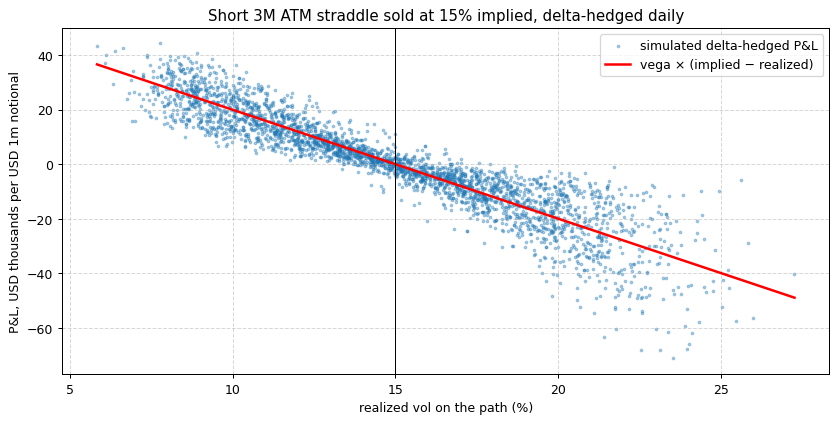

In [6]:
rng = np.random.default_rng(0)
n_paths, n_steps, T, iv = 3000, 63, 0.25, 0.15
dt = T / n_steps
true_vol = rng.uniform(0.08, 0.22, n_paths)                   # each path realizes a different vol
z = rng.standard_normal((n_paths, n_steps))
logS = np.cumsum(true_vol[:, None] * np.sqrt(dt) * z - 0.5 * true_vol[:, None]**2 * dt, axis=1)
S = np.hstack([np.ones((n_paths, 1)), np.exp(logS)])          # spot paths starting at 1.0

premium, _, vega0 = straddle(1.0, 1.0, T, iv)
hedge_pnl = np.zeros(n_paths)
for k in range(n_steps):                                      # short straddle -> hold +delta of spot
    tau = T - k * dt
    _, delta, _ = straddle(S[:, k], 1.0, tau, iv)
    hedge_pnl += delta * (S[:, k + 1] - S[:, k])
payoff = np.abs(S[:, -1] - 1.0)
pnl = (premium - payoff + hedge_pnl) * notional

rv_path = np.sqrt((np.diff(np.log(S), axis=1) ** 2).sum(axis=1) / T) * 100
approx = vega0 * notional * (iv * 100 - rv_path)

fig, ax = plt.subplots()
ax.scatter(rv_path, pnl / 1e3, s=4, alpha=.35, label="simulated delta-hedged P&L")
xs = np.sort(rv_path); ax.plot(xs, vega0 * notional * (iv * 100 - xs) / 1e3, "r", lw=2, label="vega × (implied − realized)")
ax.axvline(iv * 100, color="k", lw=.8)
ax.set_xlabel("realized vol on the path (%)"); ax.set_ylabel("P&L, USD thousands per USD 1m notional")
ax.set_title("Short 3M ATM straddle sold at 15% implied, delta-hedged daily"); ax.legend(); plt.show()
print(f"correlation between simulated P&L and the approximation: {np.corrcoef(pnl, approx)[0, 1]:.2f}")

The red line explains most of the result, but the cloud around it is wide. The scatter comes from **path dependence**: gamma is largest when spot is near the strike, so a big move late in the trade, close to the strike, costs more than the same move early on or far from the strike. Two paths with identical realized vol can have quite different P&L.

Keep this in mind: every VRP number in this notebook uses implied − realized as a stand-in for the true straddle P&L.

## 5. The volatility cone

For each window length (x-axis), compute the realized vol of **every** window of that length in history, then plot the max, min, mean and ±1/±2 standard deviations. The current ATM implied vols go on top as dots at their tenor.

The x-axis counts weekdays (the rows of the export), so 3M ≈ 65, 6M ≈ 130, 9M ≈ 195 and 1Y ≈ 261. Each window's vol is annualized on calendar time.

* Short windows have a wide cone: a few big days can make one month very volatile or very calm.
* Long windows converge to the long-run level, because shocks average out and vol mean-reverts.
* A dot near the top of the cone says options are priced for an unusually turbulent period; near the bottom, an unusually calm one.

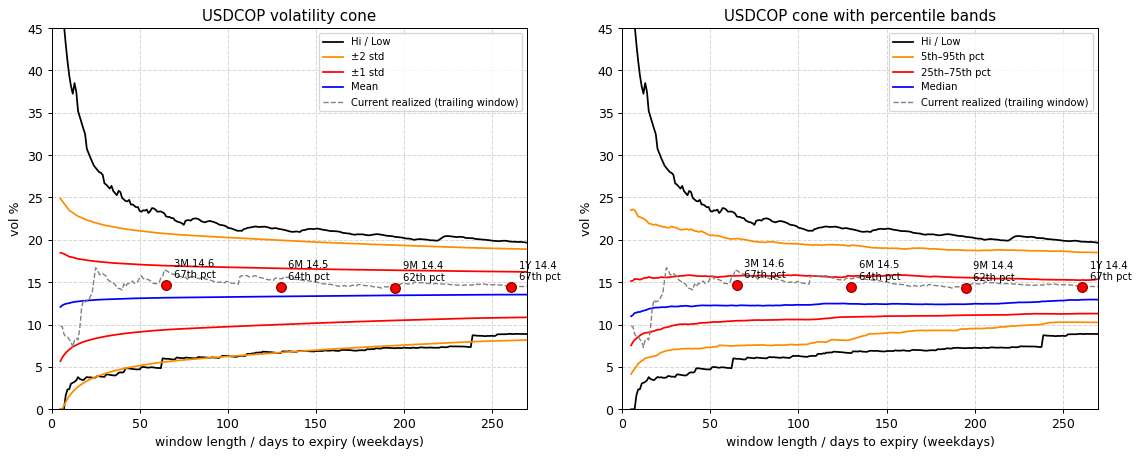

In [7]:
TD = {"3M": 65, "6M": 130, "9M": 195, "1Y": 261}          # weekdays per tenor

def rolling_rv(r, n):
    # calendar-time realized vol of every window of n consecutive returns
    c = np.concatenate([[0.0], np.cumsum(r.values ** 2)])
    price_dates = np.concatenate([[r.index[0] - pd.Timedelta(days=1)], r.index.values]).astype("datetime64[D]")
    # price_dates[k] is the date of the price before return k; window of returns i-n+1..i spans price_dates[i-n+1]..r.index[i]
    i = np.arange(n - 1, len(r))
    days = (r.index.values[i].astype("datetime64[D]") - price_dates[i - n + 1]).astype(float)
    var = c[i + 1] - c[i + 1 - n]
    return pd.Series(np.sqrt(var / (days / DAYS_PER_YEAR)) * 100, index=r.index[i])

def cone(r, max_n=270):
    rows = []
    for n in range(5, max_n + 1):
        rv = rolling_rv(r, n)
        rows.append(dict(n=n, hi=rv.max(), lo=rv.min(), mean=rv.mean(), std=rv.std(),
                         p05=rv.quantile(.05), p25=rv.quantile(.25), p50=rv.median(),
                         p75=rv.quantile(.75), p95=rv.quantile(.95), current=rv.iloc[-1]))
    return pd.DataFrame(rows).set_index("n")

def plot_cone(ax, pair, percentiles=False):
    c = cone(rets[pair])
    ax.plot(c.index, c.hi, "k", lw=1.4, label="Hi / Low"); ax.plot(c.index, c.lo, "k", lw=1.4)
    for k, colr in [(2, "darkorange"), (1, "red")]:
        if percentiles:
            up, dn = (c.p95, c.p05) if k == 2 else (c.p75, c.p25); lab = "5th–95th pct" if k == 2 else "25th–75th pct"
        else:
            up, dn = c["mean"] + k * c["std"], (c["mean"] - k * c["std"]).clip(lower=0); lab = f"±{k} std"
        ax.plot(c.index, up, color=colr, lw=1.4, label=lab); ax.plot(c.index, dn, color=colr, lw=1.4)
    ax.plot(c.index, c.p50 if percentiles else c["mean"], "b", lw=1.4, label="Median" if percentiles else "Mean")
    ax.plot(c.index, c.current, color="grey", ls="--", lw=1.1, label="Current realized (trailing window)")
    for t, n in TD.items():
        v = data[pair][f"atm_{t}"].iloc[-1]
        pct = (rolling_rv(rets[pair], n) < v).mean() * 100
        ax.scatter(n, v, s=60, color="red", edgecolor="darkred", zorder=5)
        ax.annotate(f"{t} {v:.1f}\n{pct:.0f}th pct", (n, v), xytext=(6, 6), textcoords="offset points", fontsize=8)
    ax.set_xlim(0, 270); ax.set_ylim(0, min(c.hi.max() * 1.05, 45))
    ax.set_xlabel("window length / days to expiry (weekdays)"); ax.set_ylabel("vol %"); ax.set_title(f"USD{pair} volatility cone")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
plot_cone(axes[0], "COP"); plot_cone(axes[1], "COP", percentiles=True)
axes[0].legend(fontsize=8); axes[1].legend(fontsize=8)
axes[1].set_title("USDCOP cone with percentile bands"); plt.show()

**Why the percentile version is more honest.** Vol is skewed to the upside: it can spike to 40% but cannot go below zero. The ±2 std line on the left drops to zero at short windows, which is impossible. Percentiles respect the skew.

**Try it:** change `"COP"` to `"PEN"`. PEN implied sits near the top of its cone because the central bank keeps realized vol very low, while options still price political tail risk.

## 6. Skew snapshot: risk reversals and butterflies vs their own history

Realized vol has no skew equivalent, so skew gets its own comparison: where does today's RR or BF sit within its own 2014–2026 history?

The workbook now has the **25-delta butterfly** alongside the 15-delta one. The 25d RR and 25d BF are the standard pair: they describe the same points on the smile (the 25-delta wings), so they can be read together. The 15d BF looks further out at the tails.

In [8]:
def skew_table(pair):
    rows = []
    for kind in ["rr", "bf25", "bf15"]:
        for t in ["3M", "6M", "1Y"]:
            h = data[pair][f"{kind}_{t}"].dropna(); cur = h.iloc[-1]
            rows.append(dict(metric=f"{kind.upper()} {t}", current=cur, median=h.median(),
                             p05=h.quantile(.05), p95=h.quantile(.95),
                             pctile=(h < cur).mean() * 100, z=(cur - h.mean()) / h.std()))
    return pd.DataFrame(rows).set_index("metric").round(2)

print(skew_table("COP"))

         current  median   p05   p95  pctile     z
metric                                            
RR 3M       2.60    2.05  1.40  2.76   90.91  1.20
RR 6M       2.58    2.25  1.59  2.83   77.43  0.89
RR 1Y       2.61    2.47  1.81  3.09   62.27  0.39
BF25 3M     0.57    0.44  0.33  0.65   81.17  0.72
BF25 6M     0.70    0.53  0.41  0.73   92.53  1.23
BF25 1Y     0.72    0.66  0.52  0.86   69.33  0.32
BF15 3M     1.24    1.06  0.78  1.39   77.13  0.73
BF15 6M     1.36    1.28  0.93  1.58   66.52  0.40
BF15 1Y     1.45    1.60  1.13  1.91   27.95 -0.46


COP 3M RR sits in roughly its 90th percentile while 1Y is near its median: front-end protection against peso weakness is unusually bid. Historically the RR curve slopes up (1Y above 3M), so a flat curve is itself the anomaly. That is a skew *term-structure* observation, not a level one.

The new 25d butterflies add something the 15d ones miss: COP 6M 25d wings are in their 92nd percentile, while 1Y 15d wings sit near their 28th. Which point on the smile you look at changes the story.

**Try it:** run `skew_table("BRL")` and compare 23 Oct with 27 Oct (`data["BRL"][["rr_3M", "bf25_3M"]].tail(5)`). Skew and wings both cheapened after the election, the same event-premium unwind seen in ATM vol.

## 7. The volatility risk premium (VRP)

Two definitions, and it matters which one you use:

* **Ex-post VRP** = implied vol on day *t* − realized vol over the option's life (t to t + tenor). This is what a seller of delta-hedged ATM vol actually earned (section 4). It is only known after expiry, so it measures *profitability*, not a tradable signal.
* **Ex-ante VRP** = implied vol on day *t* − realized vol over the *previous* tenor. Known on day t, so it is a candidate *signal*.

Both realized measures are calendar-time annualized over the exact calendar window, computed efficiently with cumulative sums of squared returns.

In [9]:
def window_rv(r, starts, ends):
    # calendar-time realized vol over (start, end] for many windows at once
    idx = r.index; c = np.concatenate([[0.0], np.cumsum(r.values ** 2)])
    a = idx.searchsorted(starts, side="right"); b = idx.searchsorted(ends, side="right")
    years = np.asarray((ends - starts).days, dtype=float) / DAYS_PER_YEAR
    return np.sqrt((c[b] - c[a]) / years) * 100

def vrp_frame(pair, tenor):
    r = rets[pair]; dates = r.index; m = TENORS[tenor]
    iv = data[pair][f"atm_{tenor}"].reindex(dates)
    ends = dates + pd.DateOffset(months=m); ok = ends <= dates[-1]
    starts = dates - pd.DateOffset(months=m); ok2 = starts >= dates[0]
    out = pd.DataFrame(index=dates)
    out["iv"] = iv
    out.loc[ok, "rv_fwd"] = window_rv(r, dates[ok], ends[ok])
    out.loc[ok2, "rv_trail"] = window_rv(r, starts[ok2], dates[ok2])
    out["vrp_expost"] = out.iv - out.rv_fwd
    out["vrp_exante"] = out.iv - out.rv_trail
    return out

V = {p: {t: vrp_frame(p, t) for t in TENORS} for p in PAIRS}
print(V["COP"]["3M"].dropna().tail(3).round(2))

               iv  rv_fwd  rv_trail  vrp_expost  vrp_exante
date                                                       
2026-07-23  13.09   16.30     15.13       -3.21       -2.03
2026-07-24  13.16   16.26     15.18       -3.10       -2.01
2026-07-27  13.40   16.27     14.52       -2.87       -1.13


### Measuring profitability without fooling yourself

* **Overlapping trades.** A 3M trade opened each day overlaps with the ones opened in the previous three months, so daily observations are not independent. Treating them as independent inflates the Sharpe ratio. We use only non-overlapping trades, and average over every possible starting day.
* **Sample size.** Twelve years gives about 48 independent 3M trades but only 12 one-year trades. The standard error of an annualized Sharpe ratio is roughly $\sqrt{(1 + SR^2/2)/\text{years}} \approx 0.29$ here. Differences smaller than that are noise.
* **Vol basis vs variance basis.** P&L in vol points (implied − realized) is the first-order view. Variance swaps pay $(\sigma_i^2 - \sigma_r^2)/(2\sigma_i)$ per unit of vega, which penalizes big realized moves more and is closer to what a short-gamma book feels in a crash.

In [10]:
def nonoverlap_sharpe(x, months, col):
    # annualized Sharpe of non-overlapping trades, averaged over every start offset
    idx = x.index; v = x[col].values; out = []
    for t0 in idx[idx < idx[0] + pd.DateOffset(months=months)]:
        seq, t = [], t0
        while (i := idx.searchsorted(t)) < len(idx):
            seq.append(i); t = idx[i] + pd.DateOffset(months=months)
        s = v[seq]; out.append(s.mean() / s.std(ddof=1) * np.sqrt(12 / months))
    return np.mean(out)

def vrp_stats(pair, tenor):
    x = V[pair][tenor].dropna(subset=["rv_fwd"]).copy()
    x["var_pnl"] = (x.iv**2 - x.rv_fwd**2) / (2 * x.iv)
    m = TENORS[tenor]; yrs = (x.index[-1] - x.index[0]).days / 365.25
    sr = nonoverlap_sharpe(x, m, "vrp_expost")
    return dict(pair=pair, tenor=tenor, mean_vrp=x.vrp_expost.mean(), median_vrp=x.vrp_expost.median(),
                hit_rate=(x.vrp_expost > 0).mean() * 100, worst=x.vrp_expost.min(),
                sharpe_vol=sr, sharpe_se=np.sqrt((1 + sr**2 / 2) / yrs),
                sharpe_var=nonoverlap_sharpe(x, m, "var_pnl"))

cop = pd.DataFrame([vrp_stats("COP", t) for t in TENORS]).set_index("tenor").drop(columns="pair")
print(cop.round(2))

       mean_vrp  median_vrp  hit_rate  worst  sharpe_vol  sharpe_se  sharpe_var
tenor                                                                          
3M         0.94        1.32     67.24 -11.80        0.58       0.30        0.27
6M         0.76        1.07     68.13  -9.57        0.33       0.29        0.13
9M         0.61        1.36     69.64  -8.85        0.21       0.29        0.06
1Y         0.51        1.42     66.43  -9.27        0.14       0.29        0.02


COP's premium is positive at every tenor but thin (0.5–0.9 vol points), and it decays with tenor. On a variance basis the long tenors earn almost nothing: the premium barely pays for the tail. With a standard error near 0.30, only the 3M Sharpe of 0.58 is clearly distinguishable from zero, at about two standard errors.

3M: correlation of ex-ante signal with ex-post outcome = +0.11
6M: correlation of ex-ante signal with ex-post outcome = -0.01
9M: correlation of ex-ante signal with ex-post outcome = -0.16
1Y: correlation of ex-ante signal with ex-post outcome = -0.32


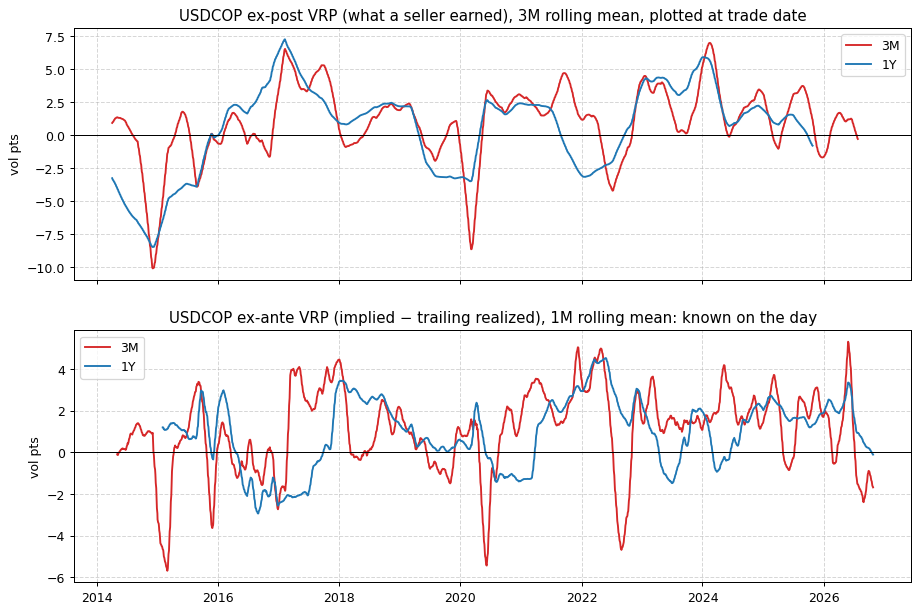

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
for t, colr in [("3M", "#d62728"), ("1Y", "#1f77b4")]:
    x = V["COP"][t]
    axes[0].plot(x.vrp_expost.rolling(63).mean(), color=colr, label=t)
    axes[1].plot(x.vrp_exante.rolling(21).mean(), color=colr, label=t)
axes[0].set_title("USDCOP ex-post VRP (what a seller earned), 3M rolling mean, plotted at trade date")
axes[1].set_title("USDCOP ex-ante VRP (implied − trailing realized), 1M rolling mean: known on the day")
for a in axes: a.axhline(0, color="k", lw=.8); a.legend(); a.set_ylabel("vol pts")
plt.show()

for t in TENORS:
    x = V["COP"][t].dropna()
    print(f"{t}: correlation of ex-ante signal with ex-post outcome = {x.vrp_exante.corr(x.vrp_expost):+.2f}")

The premium moves in regimes: deeply negative in the 2014–15 oil collapse, solidly positive in 2016–18 and 2023–24, with sharp losses around Covid and 2022.

The printout is important: the ex-ante VRP barely predicts the ex-post VRP, and at long tenors the relationship is negative. "Implied is above recent realized" is not, on its own, a reason to sell.

## 8. Across LatAm, and the equal-vega basket

      mean_vrp  median_vrp  hit_rate  worst  sharpe_vol  sharpe_se  sharpe_var
pair                                                                          
COP       0.94        1.32     67.24 -11.80        0.58       0.30        0.27
MXN       0.54        0.95     64.64 -21.67        0.30       0.29       -0.04
BRL       0.33        0.88     64.09 -14.22        0.19       0.28       -0.04
CLP       0.57        0.90     65.59 -13.38        0.37       0.29        0.12
PEN       0.75        0.98     71.17 -11.67        0.57       0.30        0.08


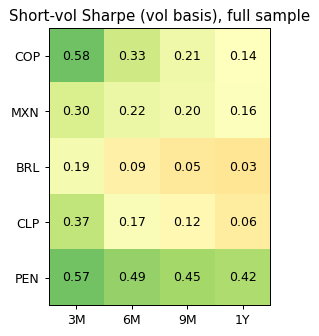

In [12]:
allstats = pd.DataFrame([vrp_stats(p, t) for p in PAIRS for t in TENORS])
piv = allstats.pivot(index="pair", columns="tenor", values="sharpe_vol")[list(TENORS)].loc[PAIRS]

fig, ax = plt.subplots(figsize=(6, 4))
ax.imshow(piv.values, cmap="RdYlGn", vmin=-.6, vmax=.9)
ax.set_xticks(range(4), piv.columns); ax.set_yticks(range(5), piv.index)
for i in range(5):
    for j in range(4): ax.text(j, i, f"{piv.values[i, j]:.2f}", ha="center", va="center")
ax.set_title("Short-vol Sharpe (vol basis), full sample"); ax.grid(False); plt.show()

print(allstats[allstats.tenor == "3M"].set_index("pair").drop(columns="tenor").round(2))

* **3M is the best tenor to sell** in every pair. PEN is the exception that holds up along the curve (0.42–0.57), because central-bank smoothing keeps its realized vol low at every horizon.
* **COP (0.58) and PEN (0.57) lead; BRL (0.19) has offered almost nothing.**
* **The annualization fix reshuffled the middle.** MXN drops from 0.40 to 0.30: the ×252 shortcut had understated its realized vol and so inflated its premium. COP moves the other way, from 0.46 to 0.58.
* **Every pair's worst trade is −12 to −22 vol points**: these are crash-insurance premia.
* **On a variance basis only COP (0.27) and CLP (0.12) stay clearly positive** at 3M.

### The equal-vega basket

**Idea:** sell the same amount of vega (say \$4,000 per vol point, i.e. a 3M straddle on about \$1m) in all five pairs. Because the pairs' premia are not perfectly correlated, the combination is smoother than any single pair in normal times.

**What it is not:** relative value. Five short-vol positions add up to a directional bet that LatAm stays calm. In a regional or global risk-off they all lose together.

In [13]:
B3 = pd.DataFrame({p: V[p]["3M"].vrp_expost for p in PAIRS}).dropna()
basket = B3.mean(axis=1)

def quick_sharpe(series):
    return nonoverlap_sharpe(series.to_frame("v"), 3, "v")

print("Non-overlapping 3M Sharpe, dates where all five pairs have data:")
for p in PAIRS: print(f"  {p}: {quick_sharpe(B3[p]):.2f}")
print(f"  Equal-vega basket: {quick_sharpe(basket):.2f}")

print("\nCorrelation of 3M VRP across pairs (non-overlapping sample):")
print(B3.iloc[::65].corr().round(2))
print("\nWorst basket trades by entry date:")
print(basket.nsmallest(3).round(2))

Non-overlapping 3M Sharpe, dates where all five pairs have data:
  COP: 0.58
  MXN: 0.30
  BRL: 0.19
  CLP: 0.37
  PEN: 0.57
  Equal-vega basket: 0.59

Correlation of 3M VRP across pairs (non-overlapping sample):
      COP   MXN   BRL   CLP   PEN
COP  1.00  0.42  0.37  0.37  0.10
MXN  0.42  1.00  0.35  0.25 -0.02
BRL  0.37  0.35  1.00  0.28  0.13
CLP  0.37  0.25  0.28  1.00  0.21
PEN  0.10 -0.02  0.13  0.21  1.00

Worst basket trades by entry date:
date
2020-02-21   -10.90
2020-02-19   -10.89
2020-02-18   -10.83
dtype: float64


**Equal vega is not equal risk.** One vol point is a much larger relative move in PEN (implied ~9) than in BRL (~15), and BRL's premium swings far more. Alternatives a vol trader may ask about:

* **Inverse-volatility (risk parity):** weight each pair by 1 / standard deviation of its VRP.
* **Percentage vega:** vega × implied vol, so a 10% relative move in vol costs the same in each pair.
* **Equal gamma:** equalize the exposure to realized moves rather than to implied.

Present equal vega as a deliberately naive benchmark, not an optimized portfolio.

**Try it:** weight the basket by `1 / B3.std()` and compare the Sharpe. Then ask yourself why that comparison is still slightly unfair (the weights use the whole sample's volatility, which you would not have known in 2014).

## 9. Relative value: a vega-neutral long/short backtest

Now the actual RV question: can we **sell the richest** pairs and **buy the cheapest**, with zero net vega, so the common LatAm risk largely cancels?

**Rules**
* Every ~21 weekdays, open a 3M position in each pair. Sell vega in the 2 pairs the signal ranks richest (weight −0.5 each), buy vega in the 2 cheapest (+0.5 each). Net vega = 0.
* Hold each position to expiry. Monthly entries mean three cohorts overlap at any time.
* Charge half the bid/offer at entry. **These spreads are my illustrative assumptions, not dealer quotes**, so results are shown at 0×, 1× and 2×.

**Daily marking.** A position struck at implied $K$ is marked like a vol swap. With a fraction $f$ of its calendar life elapsed:

$$V_t = f\,(\text{RV}_{\text{so far}} - K) + (1-f)\,(\sigma_{\text{remaining}} - K)$$

The first term is what has already been realized; the second marks the remaining life at today's implied for that remaining maturity. At entry $V = 0$; at expiry $V = \text{RV} - K$. Daily P&L is the change in $V$. Marking daily matters because short vega loses on the day implied spikes, long before expiry.

The file has no 1M or 2M vols, so the base case sets $\sigma_{\text{remaining}}$ = today's **constant-maturity 3M** implied. Section 10 tests how much that matters.

Other approximations: vol-swap rather than straddle payoff; delta-hedging costs ignored.

In [14]:
TENOR, MONTHS = "3M", 3
START = "2015-01-01"            # 2014 is warm-up for the signals
REBAL_EVERY, N_SIDE = 21, 2
HALF_SPREAD = {"COP": 0.40, "MXN": 0.15, "BRL": 0.25, "CLP": 0.35, "PEN": 0.50}   # ILLUSTRATIVE

spot_c = pd.DataFrame({p: data[p]["spot"] for p in PAIRS}).ffill()
iv_c   = pd.DataFrame({p: data[p][f"atm_{TENOR}"] for p in PAIRS}).ffill()
iv6_c  = pd.DataFrame({p: data[p]["atm_6M"] for p in PAIRS}).ffill()     # used in section 10
dates  = spot_c.index; NOBS = len(dates)
ret_c  = np.log(spot_c).diff().fillna(0.0)
c_r2   = np.vstack([np.zeros(len(PAIRS)), np.cumsum(ret_c.values ** 2, axis=0)])
day_no = np.asarray((dates - dates[0]).days, dtype=float)                # calendar day of each row

def rv_rows(i0, i1):
    # calendar-time realized vol over rows i0+1..i1, all pairs
    return np.sqrt((c_r2[i1 + 1] - c_r2[i0 + 1]) / ((day_no[i1] - day_no[i0]) / DAYS_PER_YEAR)) * 100

expiry = np.array([dates.searchsorted(d + pd.DateOffset(months=MONTHS)) for d in dates])
expiry = np.where(expiry >= NOBS, -1, expiry)
trail = pd.DataFrame(np.nan, index=dates, columns=PAIRS); expost = trail.copy()
for i, d in enumerate(dates):
    if d - pd.DateOffset(months=MONTHS) >= dates[0]:
        trail.iloc[i] = rv_rows(dates.searchsorted(d - pd.DateOffset(months=MONTHS)), i)
    if expiry[i] > 0:
        expost.iloc[i] = rv_rows(i, expiry[i])
print("calendar ready:", dates[0].date(), "to", dates[-1].date(), f"({NOBS} rows)")

calendar ready: 2014-01-01 to 2026-10-27 (3345 rows)


### Signals (higher = richer = sell)

All use only information available on the trade date.

1. **Ex-ante VRP**: implied − trailing 3M realized, in vol points.
2. **Implied / realized ratio**: the same idea scaled by vol level, so a 1-point gap in PEN counts more than in BRL.
3. **Implied percentile vs own realized history**: where today's implied sits within every 3M realized vol the pair has produced so far (expanding window).
4. **Historical VRP %**: the pair's average past premium as a % of implied, using only trades that had already expired.
5. **Implied z-score vs its own past year**: is implied high relative to where implied has been recently?

In [15]:
rv3m_hist = pd.DataFrame({p: rolling_rv(ret_c[p].iloc[1:], 65) for p in PAIRS}).reindex(dates)

def build_signals():
    S = {}
    S["Ex-ante VRP"] = iv_c - trail
    S["IV/RV ratio"] = iv_c / trail
    pct = pd.DataFrame(np.nan, index=dates, columns=PAIRS)
    for j, p in enumerate(PAIRS):
        h, v = rv3m_hist[p].values, iv_c[p].values
        for i in range(NOBS):
            past = h[: i + 1]; past = past[~np.isnan(past)]
            if len(past) >= 250: pct.iat[i, j] = (past < v[i]).mean()
    S["IV pct vs own history"] = pct
    hist = pd.DataFrame(np.nan, index=dates, columns=PAIRS)
    vrp_pct = ((iv_c - expost) / iv_c).values
    for i in range(NOBS):
        ok = (expiry[: i + 1] >= 0) & (expiry[: i + 1] <= i)          # only expired trades
        if ok.sum() >= 120: hist.iloc[i] = np.nanmean(vrp_pct[: i + 1][ok], axis=0)
    S["Historical VRP"] = hist
    S["IV z-score (1y)"] = (iv_c - iv_c.rolling(252).mean()) / iv_c.rolling(252).std()
    return S

signals = build_signals()
print("today's signal ranks (5 = richest):")
print(pd.DataFrame({k: s.iloc[-1].rank() for k, s in signals.items()}).T)

today's signal ranks (5 = richest):
                       COP  MXN  BRL  CLP  PEN
Ex-ante VRP            2.0  4.0  1.0  3.0  5.0
IV/RV ratio            2.0  4.0  1.0  3.0  5.0
IV pct vs own history  4.0  2.0  1.0  3.0  5.0
Historical VRP         4.0  2.0  1.0  3.0  5.0
IV z-score (1y)        2.0  5.0  4.0  3.0  1.0


In [16]:
def remaining_vol(i, d, f, K, mark):
    # implied vol used to mark the unexpired part of a trade opened at row i, on row d
    tau = MONTHS * (1 - f)                                       # months left
    iv3, iv6 = iv_c.values[d], iv6_c.values[d]
    if mark == "cm3m":                                           # base case: constant-maturity 3M
        return iv3
    level = iv3 + (iv6 - iv3) / 3 * (tau - 3)                    # extrapolate curve slope to remaining maturity
    if mark == "curve":
        return level
    w = np.sqrt(3 / np.maximum(tau, 0.25))                       # short-dated vol moves more ("weighted vega")
    if mark == "sqrt":
        return K + (iv3 - K) * w
    if mark == "both":
        return K + (level - K) * w

def run(weights_fn, cost_mult=1.0, mark="cm3m"):
    pnl = np.zeros((NOBS, len(PAIRS))); book = []
    spread = np.array([HALF_SPREAD[p] for p in PAIRS])
    for i in range(dates.searchsorted(pd.Timestamp(START)), NOBS, REBAL_EVERY):
        j = expiry[i]
        if j < 0: break
        w = weights_fn(i)
        if w is None: continue
        K = iv_c.values[i]; V_prev = np.zeros(len(PAIRS))
        for d in range(i + 1, j + 1):
            f = (day_no[d] - day_no[i]) / (day_no[j] - day_no[i])
            V = f * (rv_rows(i, d) - K) + (1 - f) * (remaining_vol(i, d, f, K, mark) - K) if d < j else rv_rows(i, j) - K
            pnl[d] += w * (V - V_prev); V_prev = V
        pnl[i] -= np.abs(w) * spread * cost_mult
        book.append((dates[i], w))
    return pd.DataFrame(pnl, index=dates, columns=PAIRS).loc[START:], book

def long_short(sig):
    def f(i):
        s = sig.iloc[i]
        if s.isna().any(): return None
        rk = s.rank().values; w = np.zeros(len(PAIRS))
        w[rk > len(PAIRS) - N_SIDE] = -1 / N_SIDE       # richest: sell vega
        w[rk <= N_SIDE] = +1 / N_SIDE                   # cheapest: buy vega
        return w
    return f

short_basket = lambda i: np.full(len(PAIRS), -1 / len(PAIRS))

def newey_west_se(x, lags=3):
    x = np.asarray(x) - np.mean(x); n = len(x); s = x @ x / n
    for L in range(1, lags + 1): s += 2 * (1 - L / (lags + 1)) * (x[L:] @ x[:-L]) / n
    return np.sqrt(s / n)

def perf(daily, ref=None):
    m = daily.sum(axis=1).resample("ME").sum(); eq = daily.sum(axis=1).cumsum()
    out = dict(total_pnl=eq.iloc[-1], sharpe=m.mean() / m.std() * np.sqrt(12),
               t_stat=m.mean() / newey_west_se(m.values), monthly_vol=m.std(),
               max_drawdown=(eq - eq.cummax()).min(), worst_month=m.min())
    if ref is not None: out["corr_to_short_basket"] = m.corr(ref.sum(axis=1).resample("ME").sum())
    return out

**Units.** P&L is in vol points × vega units. If one vega unit is \$10,000 per vol point, a total of 50 is about \$500,000 over the whole sample. Sharpe ratios and t-stats do not depend on the unit.

The next cell runs every signal at three cost levels (a minute or two).

In [17]:
base, _ = run(short_basket)
rows, curves, books = [], {}, {}
for name, sig in signals.items():
    for cm in [0, 1, 2]:
        d, book = run(long_short(sig), cm)
        rows.append(dict(signal=name, costs=f"{cm}x", **perf(d, base)))
        if cm == 1: curves[name], books[name] = d, book
for cm in [0, 1, 2]:
    d, _ = run(short_basket, cm); rows.append(dict(signal="Short-all basket", costs=f"{cm}x", **perf(d)))
    if cm == 1: curves["Short-all basket"] = d
results = pd.DataFrame(rows).set_index(["signal", "costs"])
print(results.round(2))

                             total_pnl  sharpe  t_stat  monthly_vol  max_drawdown  worst_month  corr_to_short_basket
signal                costs                                                                                         
Ex-ante VRP           0x         85.84    0.58    1.89         3.59        -40.08       -20.23                  0.23
                      1x        -10.24   -0.07   -0.23         3.58        -50.50       -20.80                  0.23
                      2x       -106.31   -0.73   -2.38         3.57       -120.33       -21.38                  0.24
IV/RV ratio           0x         70.77    0.45    1.43         3.82        -50.25       -20.90                  0.19
                      1x        -25.76   -0.17   -0.52         3.81        -71.59       -21.53                  0.19
                      2x       -122.28   -0.78   -2.50         3.80       -139.37       -22.15                  0.19
IV pct vs own history 0x        160.09    0.97    2.87         4

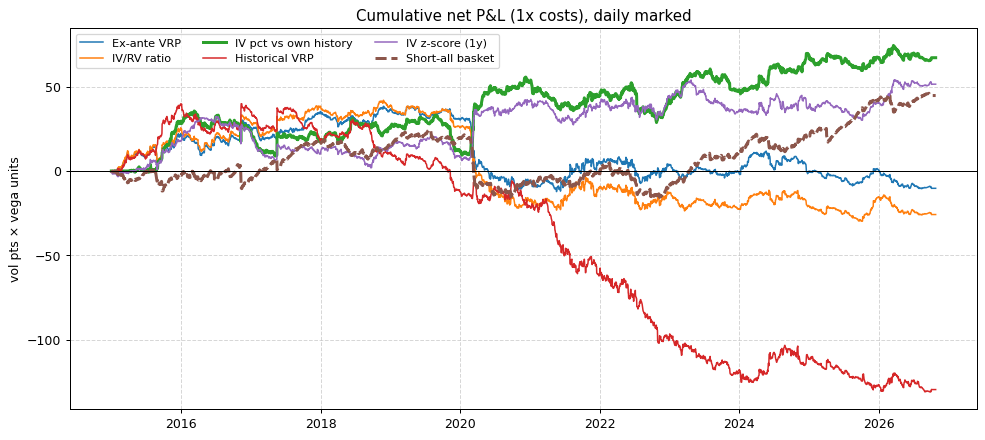

In [18]:
fig, ax = plt.subplots(figsize=(13, 5.5))
for k, d in curves.items():
    ax.plot(d.sum(axis=1).cumsum(), lw=2.4 if k in ("IV pct vs own history", "Short-all basket") else 1.2,
            ls="--" if k == "Short-all basket" else "-", label=k)
ax.axhline(0, color="k", lw=.8); ax.legend(ncol=3, fontsize=9)
ax.set_title("Cumulative net P&L (1x costs), daily marked"); ax.set_ylabel("vol pts × vega units"); plt.show()

**Reading the table**

* **Costs decide everything.** Rebuilding the book monthly pays the spread on every unit of vega, cutting 0.5–0.6 from every Sharpe. The intuitive ex-ante VRP signal goes from 0.58 to slightly negative.
* **Two signals have a convincing pre-cost edge**: "IV pct vs own history" (Sharpe 0.97, t 2.9) and "IV z-score" (0.95, t 3.2). Both ask whether implied is high relative to the pair's own past, so they are related rather than independent confirmations. After 1× costs they fall to 0.41 and 0.33, with t-stats around 1.1–1.2: not statistically significant.
* **Historical VRP loses steadily** (−0.75 after costs). Selling the pairs that were richest in the past and buying the cheapest did not work. Past richness did not persist.
* **Multiple testing.** Five signals were tried and we are looking at the best ones. A t-stat of 3 found that way is suggestive, not proof.

## 10. How much does marking with constant-maturity 3M vol matter?

One month into a 3M trade, the position is really a 2M option, but the base case marks it at today's 3M vol. A correct mark would differ in two ways:

* **Roll-down.** If the vol curve slopes up, a 3M option's implied falls as it ages into a 2M option, so a short-vol position earns carry along the way. If the curve is inverted (as in a crisis), the opposite.
* **Short-dated vol moves more.** In a sell-off, 1M and 2M implied spike harder than 3M. Marking at 3M understates the mark-to-market hit on short vol, and the gain on long vol, exactly when it matters.

Without 1M/2M quotes we test three approximations: `curve` extrapolates the remaining-life vol from the 3M−6M slope; `sqrt` scales implied moves by √(3M / time remaining), the "weighted vega" rule FX desks use; `both` combines them.

**What to expect before running it:** every trade is held to expiry and pays RV − K whatever the marks were, so **total P&L cannot change**. Only *when* gains and losses show up changes, which affects Sharpe, drawdowns and worst months.

In [19]:
print("Average 6M − 3M implied (vol pts):", (iv6_c - iv_c).mean().round(2).to_dict())
print("Most inverted 6M − 3M in Mar–Apr 2020:", (iv6_c - iv_c).loc["2020-03":"2020-04"].min().round(2).to_dict())
print()
mark_rows = []; mark_daily = {}
tests = {"Short-all basket": short_basket, "IV pct vs own history": long_short(signals["IV pct vs own history"]),
         "IV z-score (1y)": long_short(signals["IV z-score (1y)"]), "Ex-ante VRP": long_short(signals["Ex-ante VRP"])}
for name, fn in tests.items():
    for mark in ["cm3m", "curve", "sqrt", "both"]:
        d, _ = run(fn, 1, mark); mark_daily[(name, mark)] = d
        m = d.sum(axis=1).resample("ME").sum()
        mark_rows.append(dict(strategy=name, marking=mark, **perf(d), mar_2020=m.loc["2020-03"].sum()))
marks = pd.DataFrame(mark_rows).set_index(["strategy", "marking"])
print(marks.drop(columns="t_stat").round(2))

Average 6M − 3M implied (vol pts): {'COP': -0.02, 'MXN': 0.22, 'BRL': 0.03, 'CLP': -0.06, 'PEN': 0.29}
Most inverted 6M − 3M in Mar–Apr 2020: {'COP': -2.85, 'MXN': -5.1, 'BRL': -3.71, 'CLP': -1.97, 'PEN': -0.1}

                               total_pnl  sharpe  monthly_vol  max_drawdown  worst_month  mar_2020
strategy              marking                                                                     
Short-all basket      cm3m         44.67    0.30         3.63        -40.09       -24.22    -24.22
                      curve        44.67    0.29         3.74        -40.49       -25.08    -25.08
                      sqrt         44.67    0.27         4.01        -41.04       -26.89    -26.89
                      both         44.67    0.26         4.19        -42.13       -28.15    -28.15
IV pct vs own history cm3m         67.06    0.41         4.00        -26.88       -14.00     20.75
                      curve        67.06    0.40         4.09        -27.51       -14.24     21

* **Total P&L is identical under every marking**, as expected.
* **Risk statistics get worse.** Monthly P&L volatility rises by up to ~20%, Sharpe falls 0.01–0.05, and worst months get 1–4 points worse. The basket's March 2020 loss deepens from −24.2 to −28.2; the IV-pct long/short's March 2020 gain grows from 20.8 to 24.2.
* **The vol-of-vol effect dominates.** LatAm vol curves have been nearly flat on average (6M − 3M of −0.06 to +0.29), so roll-down barely matters. The √-time scaling, i.e. short-dated vol moving more in a crisis, does most of the damage.
* **Conclusions are unchanged.** The crisis-hedge correlation is intact and nothing clears costs significantly.

Two caveats. These adjustments are themselves estimates: real 1M vol can spike well beyond what a 3M−6M extrapolation implies, so the true worst months may be worse still. And if you exit early, run stop-losses or have mark-to-market risk limits, the marks become realized P&L, so the approximation would affect returns, not just risk statistics.

## 11. Diagnosing the result: where does the P&L come from?

Share of entries short / long vega by pair:
        COP   MXN   BRL  CLP   PEN
short  0.15  0.40  0.09  0.7  0.70
long   0.43  0.45  0.79  0.1  0.23

Net P&L by pair: {'COP': -27.6, 'MXN': 20.1, 'BRL': -6.3, 'CLP': 29.0, 'PEN': 51.8}

Sharpe if you just held the average positions: -0.54
Sharpe of the signal (dynamic):                 0.41
Net P&L by year: {2015: 29.5, 2016: -6.0, 2017: -6.0, 2018: 7.8, 2019: -13.5, 2020: 41.1, 2021: -8.0, 2022: -2.8, 2023: 5.1, 2024: 21.5, 2025: -1.7, 2026: 0.1}
Net Sharpe excluding 2015 and 2020: -0.03


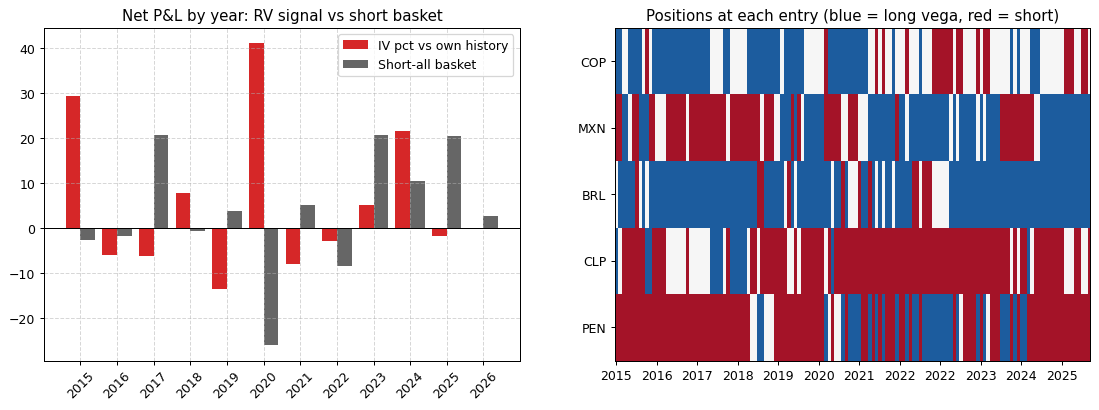

In [20]:
best = "IV pct vs own history"
d = curves[best]; b = curves["Short-all basket"]
W = pd.DataFrame([w for _, w in books[best]], index=[t for t, _ in books[best]], columns=PAIRS)

print("Share of entries short / long vega by pair:")
print(pd.DataFrame({"short": (W < 0).mean(), "long": (W > 0).mean()}).T.round(2))
print("\nNet P&L by pair:", d.sum().round(1).to_dict())

static, _ = run(lambda i: W.mean().values, 1)          # hold the average positions constant
print(f"\nSharpe if you just held the average positions: {perf(static)['sharpe']:.2f}")
print(f"Sharpe of the signal (dynamic):                 {perf(d)['sharpe']:.2f}")

py = d.sum(axis=1).groupby(d.index.year).sum(); by = b.sum(axis=1).groupby(b.index.year).sum()
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
x = np.arange(len(py))
axes[0].bar(x - .2, py, .4, color="#d62728", label=best); axes[0].bar(x + .2, by, .4, color="k", alpha=.6, label="Short-all basket")
axes[0].set_xticks(x, py.index, rotation=45); axes[0].axhline(0, color="k", lw=.8); axes[0].legend()
axes[0].set_title("Net P&L by year: RV signal vs short basket")
axes[1].imshow(W.T.values, aspect="auto", cmap="RdBu", vmin=-.6, vmax=.6, interpolation="nearest")
axes[1].set_yticks(range(5), PAIRS); tk = np.arange(0, len(W), 12); axes[1].set_xticks(tk, [W.index[i].year for i in tk])
axes[1].set_title("Positions at each entry (blue = long vega, red = short)"); axes[1].grid(False)
plt.show()

m = d.sum(axis=1).resample("ME").sum(); calm = m[~m.index.year.isin([2015, 2020])]
print("Net P&L by year:", py.round(1).to_dict())
print(f"Net Sharpe excluding 2015 and 2020: {calm.mean() / calm.std() * np.sqrt(12):.2f}")

**What the signal is really doing**

* It is long BRL vol most of the time (79% of entries). BRL's realized history contains huge spikes, so today's implied usually looks low against it. It is mostly short PEN and CLP (70% each), whose implied looks high against a calm realized history.
* Holding the average positions constant loses money (Sharpe −0.54 vs +0.41). The edge comes from **timing**, not from a hidden fixed tilt.
* 2015 (+29.5) and 2020 (+41.1) produced more than the whole net P&L. Excluding those years, the net Sharpe is about zero.

So it behaves like **crisis insurance**: negatively correlated with the short-vol basket, earning when the basket loses. That suggests one more idea.

In [21]:
p = d.sum(axis=1); bb = b.sum(axis=1)
for lam in [0, 0.25, 0.5, 1.0]:
    x = bb + lam * p; mm = x.resample("ME").sum()
    print(f"short basket + {lam:.2f} × RV overlay: Sharpe {mm.mean() / mm.std() * np.sqrt(12):.2f}, worst month {mm.min():6.1f}")

short basket + 0.00 × RV overlay: Sharpe 0.30, worst month  -24.2
short basket + 0.25 × RV overlay: Sharpe 0.43, worst month  -19.0
short basket + 0.50 × RV overlay: Sharpe 0.53, worst month  -14.1
short basket + 1.00 × RV overlay: Sharpe 0.60, worst month  -21.1


Adding half a unit of the RV signal to the short-vol basket raises the Sharpe from 0.30 to 0.53 and cuts the worst month from −24.2 to −14.1.

**But the mix was chosen after seeing the data.** This is a hypothesis to test going forward, not a result.

## 12. Before you show this to a vol trader

**State these limits yourself:**

1. **Costs are assumptions.** Ask what real bid/offers are in each pair; it is the single number that decides whether any of this is tradable.
2. **Proxy P&L.** Implied − realized approximates a delta-hedged straddle; section 4 showed the path-dependent scatter around it. Vol swaps are thin in these pairs.
3. **Marking.** Constant-maturity 3M implied is used for the remaining life. Section 10 shows this flatters risk statistics, not total P&L. 1M and 2M quotes would let you mark properly.
4. **Fixings.** NDF options settle on fixings (TRM, PTAX…), not Bloomberg closes.
5. **Skew ignored.** Everything is ATM. A short straddle book is also short the wings.
6. **Statistics.** ~48 independent 3M trades; Sharpe standard error ~0.29; five signals tested.
7. **Events.** Elections and policy shocks drive the worst losses. Implied drops once a known event has passed, as BRL did after the 2026 runoff.

**The defensible claim:** cross-sectional LatAm vol RV does not clear realistic costs on this data. Two related signals, both comparing implied with the pair's own history, show a crisis-concentrated gross edge that is negatively correlated with short vol, so they are worth testing as a tail hedge for a short-vol book.

### Exercises

1. **Tenor.** Set `TENOR, MONTHS = "6M", 6` in section 9 and rerun (also set `iv6_c` to the 1Y column so the curve-slope marking still looks one tenor further out). Costs are paid once per position, so longer tenors spread them over more time. Which signals improve?
2. **Concentration.** Set `N_SIDE = 1` (one pair each side). Does the best signal still work?
3. **Breakeven costs.** Find the cost multiple at which "IV pct vs own history" has zero Sharpe.
4. **Risk weighting.** Replace `±1/N_SIDE` with weights scaled by 1 / each pair's trailing VRP volatility. Use only past data.
5. **Variance basis.** Change the marking to variance-swap terms and see which signals survive.
6. **Skew signals.** Build a signal from the RR percentile (`data[p]["rr_3M"]`) or the 25d BF, and test it the same way.
7. **Annualization.** Swap `rv_rows` back to "average daily variance × 252" and see which pairs' VRP and which signal rankings move.